# Workflow 1 / SQ1: is the feature-relevance ranking stable over time?

**Group 17, Theme 17 (Track D), Maria Inês.** This notebook documents *what was run, how, and why* for SQ1, with links to the files.
It **only reads saved results** from [wf1_stability/](../wf1_stability/); it never re-runs the model. The general background is in [findings.ipynb](findings.ipynb).

> **SQ1.** Do the learned feature-relevance weights stay stable over time when the stream is (nearly) stationary, and is Elec2 less stable than a shuffled copy of itself?

## 1. The prequential loop in five lines

Source: `prequential_nf_generic` in [exp_sota_comparison.py](../exp_sota_comparison.py) (check the line numbers in your copy before citing them).

1. The stream is read once, in order, and the model starts empty. At t=0 it predicts class 0.
2. At each step t the model predicts ŷₜ from xₜ **before** it sees the label.
3. The prediction is compared with yₜ and the running correct count and cumulative accuracy are updated.
4. Only then does `partial_fit(xₜ, yₜ)` run: rules are created, updated or pruned and the sample enters the 200-sample buffer.
5. Every 50 samples the global weights **G** are recomputed from the last 200 samples. G is what SQ1 tracks. Our logger only reads G after the step and cannot change a prediction ([tests/test_nonintrusive.py](../tests/test_nonintrusive.py)).

> **Conclusion (section 1).** SQ1 measures G, which the baseline refreshes every 50 samples from the last 200 samples it has already seen. Because every sample is predicted before it is learned and our logger only reads G after the step, the numbers below describe the unmodified baseline, and G at time t uses no future data.

## 2. Protocol (summary)

Full text: [PROTOCOL_SQ1.md](../wf1_stability/PROTOCOL_SQ1.md).

| Item | Choice | Why |
|---|---|---|
| Primary metric | top-k Jaccard of G between snapshots **200 samples** apart; k=2 on synthetic, k=3 on Elec2 | 200 = the buffer length, so the two windows share no samples |
| Secondary metrics | Kendall τ-b, weighted τ, Spearman, top-k switches per 1000, per-feature SD | rank agreement beyond the top-k; how often the set changes |
| Lags | 50, 100, 150, 200, 500, 2000 | lags below 200 overlap windows (lag 50 = 75% overlap) and are flagged as such |
| Segments | stationary only, buffer flushed (200 samples) after any drift | avoids measuring the drift itself |
| Elec2 CI | moving-block bootstrap, 500-sample blocks | checkpoints are autocorrelated |
| Primary test | exact one-sided p = (1 + hits) / (N + 1) against N shuffled copies | one real stream cannot be tested with a paired test |
| S3 | sanity check only (should be about 1) | stationary synthetic stream |

Code: [relevance/stability.py](../relevance/stability.py) (metrics), [relevance/stats.py](../relevance/stats.py) (bootstrap, Wilcoxon, Holm, shuffle p), tests in [tests/test_stability.py](../tests/test_stability.py) including the *stable top-k with shuffled irrelevant features* case (Jaccard = 1.0 while τ-b ≈ 0.37).

> **Conclusion (section 2).** Lag 200 is the smallest lag at which two snapshots share no samples, so it is the first lag where a drop in Jaccard cannot be blamed on overlapping windows; shorter lags are reported only to show how much overlap inflates stability. Jaccard asks whether the *set* is the same and τ-b asks whether the *order* is, and the two can disagree (see the unit test), which is why both are reported. With one real Elec2 stream, a permutation test against its own shuffles is the only valid test, and its smallest p-value is set by the number of shuffles.

## 3. What was run

All runs use [run_relevance.py](../run_relevance.py) with the configs in [wf1_stability/configs/](../wf1_stability/configs/). Raw per-run files go to `results_relevance/` and are **not committed** (regenerate them with the commands in section 8).

| Condition | Config | Runs | Notes |
|---|---|---|---|
| S1 | [configs/mve.json](../configs/mve.json) | 3 | synthetic stream with a drift at 10,000 |
| S3 | [configs/s3.json](../wf1_stability/configs/s3.json) | 10 | stationary synthetic, relevant features {0, 1}, k=2 |
| Elec2 | [elec2.json](../wf1_stability/configs/elec2.json) | 1 | the model is deterministic, so one run |
| Elec2 shuffled | [elec2_shuffled.json](../wf1_stability/configs/elec2_shuffled.json) | 30 | seed = permutation |
| Elec2, no `date` | [elec2_nodate.json](../wf1_stability/configs/elec2_nodate.json) | 1 | sensitivity check |
| Elec2 shuffled, no `date` | [elec2_shuffled_nodate.json](../wf1_stability/configs/elec2_shuffled_nodate.json) | 30 | sensitivity check |

**Why these choices**

- **Fixed "domain" scaling for Elec2** (`day` → (day−1)/6, other features as they are). The baseline's whole-stream min-max scaling uses future information, and an expanding min-max collapses the monotone `date` feature in the original order but not when shuffled, which would bias the comparison. With domain scaling the accuracy is 0.5915, the same as the baseline's 0.591, so the scaling does not distort the model.
- **No-`date` variant.** In the original order `date` rises monotonically inside every window; shuffled, it is spread over the whole range. The between/within variance ratio behind G can behave very differently, so the whole comparison was repeated without it.
- **30 shuffles.** With N shuffles the smallest possible p is 1/(N+1). 10 shuffles give 0.091 and could never reach 0.05; 30 give 0.032.

> **Conclusion (section 3).** The design gives two like-for-like contrasts (real vs shuffled Elec2, with and without `date`) plus S3 as a sanity check. The preprocessing does not distort the model (accuracy 0.5915 vs the baseline's 0.591). The shuffled stream scores lower (about 0.5625, below the majority rate of 0.567), so shuffling removes the temporal structure the model exploits; that is the point of the control, but it means the two conditions are not the same task for the classifier, only for the relevance estimator.

In [1]:
from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, Image, display

ROOT = Path.cwd()
if not (ROOT / "wf1_stability").exists():
    ROOT = ROOT.parent
SQ1 = ROOT / "wf1_stability"

def show_md(name):
    p = SQ1 / name
    display(Markdown(p.read_text(encoding="utf-8")) if p.exists()
            else Markdown(f"*{name} not found. Run `python wf1_stability/analyze_sq1.py` first.*"))

def read_runs(sfx=""):
    with open(SQ1 / f"sq1_per_run{sfx}.csv", encoding="utf-8") as f:
        return list(csv.DictReader(f))

def values(rows, cond, key):
    return np.array([float(r[key]) for r in rows if r["condition"] == cond], float)

## 4. Results with `date` included

Generated by `analyze_sq1.py`: [table1_sq1.md](../wf1_stability/table1_sq1.md), per-run values in [sq1_per_run.csv](../wf1_stability/sq1_per_run.csv).

In [2]:
show_md('table1_sq1.md')

## SQ1: stability of the global relevance weights G (stationary segments, buffer flushed)

Primary metric: top-k Jaccard at lag 200 samples (no window overlap). Mean ± SD over runs; CI = 95%.

| condition | k | runs | **Jaccard@200** | 95% CI | tau-b@200 | weighted tau@200 | Spearman@200 | top-k switches /1000 | mean SD of weights |
|---|---|---|---|---|---|---|---|---|---|
| S1 | 3 | 3 | **1.000 ± 0.000** | [1.000, 1.000] (bootstrap over runs) | 0.465 ± 0.008 | 0.609 ± 0.007 | 0.636 ± 0.007 | 0.00 ± 0.00 | 0.065 ± 0.001 |
| S3 | 2 | 10 | **1.000 ± 0.000** | [1.000, 1.000] (bootstrap over runs) | 0.356 ± 0.011 | 0.565 ± 0.009 | 0.486 ± 0.011 | 0.00 ± 0.00 | 0.037 ± 0.001 |
| Elec2 | 3 | 1 | **0.648 ± n/a** | [0.601, 0.693] (block bootstrap (500-sample blocks)) | 0.839 ± n/a | 0.861 ± n/a | 0.922 ± n/a | 8.16 ± n/a | 0.043 ± n/a |
| Elec2 shuffled | 3 | 30 | **0.769 ± 0.026** | [0.760, 0.778] (bootstrap over runs) | 0.897 ± 0.008 | 0.920 ± 0.007 | 0.957 ± 0.005 | 5.13 ± 0.74 | 0.013 ± 0.001 |

### Primary test: Elec2 against its shuffled distribution

Elec2 Jaccard@200 = 0.648 (95% CI 0.601-0.693, block bootstrap (500-sample blocks)); shuffled mean = 0.769 ± 0.026 over 30 shuffles. One-sided exact p (Elec2 lower than shuffled) = 0.032; the smallest possible p with 30 shuffles is 0.032.

### Sanity check S3 (stationary synthetic)

Jaccard@200 = 1.000 (expected about 1). Within-run SD over checkpoints = 0.000; between-seed SD of run means = 0.000.

### Effect of window overlap (lags below 200)

Mean Jaccard by lag. The model's buffer holds 200 samples, so snapshots `lag` apart share `1 - lag/200` of their data.

| condition | lag 50 (75% overlap) | lag 100 (50% overlap) | lag 150 (25% overlap) | lag 200 (0% overlap) | lag 500 (0% overlap) | lag 2000 (0% overlap) |
|---|---|---|---|---|---|---|
| S1 | 1.000 | 1.000 | 1.000 | 1.000 | 1.000 | 1.000 |
| S3 | 1.000 | 1.000 | 1.000 | 1.000 | 1.000 | 1.000 |
| Elec2 | 0.788 | 0.715 | 0.684 | 0.648 | 0.693 | 0.692 |
| Elec2 shuffled | 0.871 | 0.829 | 0.796 | 0.769 | 0.772 | 0.772 |


> **Conclusion (section 4, with `date`).** On Elec2 every stability measure is lower than under shuffling: Jaccard@200 0.648 [0.601, 0.693] vs 0.769 ± 0.026 [0.760, 0.778], τ-b 0.839 vs 0.897, weighted τ 0.861 vs 0.920, Spearman 0.922 vs 0.957, top-k switches 8.2 vs 5.1 per 1000, and the weights move about 3.3 times more (mean SD 0.043 vs 0.013). The two confidence intervals do not overlap. On the synthetic streams the top-k is perfectly stable (Jaccard 1.000), which is the expected sanity result but also means they cannot discriminate between conditions. Their low τ-b (0.356 on S3, close to the 0.37 of the unit test) is not instability: it is the ordering of the irrelevant features, which carries no signal.

## 5. Results without `date` (sensitivity)

[table1_sq1_nodate.md](../wf1_stability/table1_sq1_nodate.md), [sq1_per_run_nodate.csv](../wf1_stability/sq1_per_run_nodate.csv).

In [3]:
show_md('table1_sq1_nodate.md')

## SQ1: stability of the global relevance weights G (stationary segments, buffer flushed)

Primary metric: top-k Jaccard at lag 200 samples (no window overlap). Mean ± SD over runs; CI = 95%.

| condition | k | runs | **Jaccard@200** | 95% CI | tau-b@200 | weighted tau@200 | Spearman@200 | top-k switches /1000 | mean SD of weights |
|---|---|---|---|---|---|---|---|---|---|
| S1 | 3 | 3 | **1.000 ± 0.000** | [1.000, 1.000] (bootstrap over runs) | 0.465 ± 0.008 | 0.609 ± 0.007 | 0.636 ± 0.007 | 0.00 ± 0.00 | 0.065 ± 0.001 |
| S3 | 2 | 10 | **1.000 ± 0.000** | [1.000, 1.000] (bootstrap over runs) | 0.356 ± 0.011 | 0.565 ± 0.009 | 0.486 ± 0.011 | 0.00 ± 0.00 | 0.037 ± 0.001 |
| Elec2 | 3 | 1 | **0.702 ± n/a** | [0.663, 0.744] (block bootstrap (500-sample blocks)) | 0.874 ± n/a | 0.888 ± n/a | 0.944 ± n/a | 6.73 ± n/a | 0.044 ± n/a |
| Elec2 shuffled | 3 | 30 | **0.883 ± 0.024** | [0.875, 0.892] (bootstrap over runs) | 0.961 ± 0.007 | 0.967 ± 0.006 | 0.985 ± 0.003 | 2.74 ± 0.57 | 0.013 ± 0.001 |

### Primary test: Elec2 against its shuffled distribution

Elec2 Jaccard@200 = 0.702 (95% CI 0.663-0.744, block bootstrap (500-sample blocks)); shuffled mean = 0.883 ± 0.024 over 30 shuffles. One-sided exact p (Elec2 lower than shuffled) = 0.032; the smallest possible p with 30 shuffles is 0.032.

### Sanity check S3 (stationary synthetic)

Jaccard@200 = 1.000 (expected about 1). Within-run SD over checkpoints = 0.000; between-seed SD of run means = 0.000.

### Effect of window overlap (lags below 200)

Mean Jaccard by lag. The model's buffer holds 200 samples, so snapshots `lag` apart share `1 - lag/200` of their data.

| condition | lag 50 (75% overlap) | lag 100 (50% overlap) | lag 150 (25% overlap) | lag 200 (0% overlap) | lag 500 (0% overlap) | lag 2000 (0% overlap) |
|---|---|---|---|---|---|---|
| S1 | 1.000 | 1.000 | 1.000 | 1.000 | 1.000 | 1.000 |
| S3 | 1.000 | 1.000 | 1.000 | 1.000 | 1.000 | 1.000 |
| Elec2 | 0.832 | 0.759 | 0.735 | 0.702 | 0.743 | 0.739 |
| Elec2 shuffled | 0.931 | 0.910 | 0.894 | 0.883 | 0.887 | 0.885 |


### Recomputing the primary test from the per-run CSV

This cell does not trust the tables above: it recomputes the exact shuffle p-value from the saved per-run values.

In [4]:
def primary(sfx, key="jaccard@200"):
    rows = read_runs(sfx)
    real = values(rows, "Elec2", key)[0]
    null = values(rows, "Elec2 shuffled", key)
    hits = int((null <= real).sum())
    return dict(real=real, null_mean=null.mean(), null_sd=null.std(ddof=1), n=len(null), hits=hits,
                p=(1 + hits) / (len(null) + 1), z=(real - null.mean()) / null.std(ddof=1))

for label, sfx in [("with date", ""), ("without date", "_nodate")]:
    try:
        r = primary(sfx)
        print(f"{label:13s} real={r['real']:.3f}  shuffled={r['null_mean']:.3f} ± {r['null_sd']:.3f} (n={r['n']})  "
              f"shuffles at or below real: {r['hits']}  exact p={r['p']:.3f}  z={r['z']:.1f}")
    except FileNotFoundError:
        print(label, ": per-run CSV not found")

with date     real=0.648  shuffled=0.769 ± 0.026 (n=30)  shuffles at or below real: 0  exact p=0.032  z=-4.7
without date  real=0.702  shuffled=0.883 ± 0.024 (n=30)  shuffles at or below real: 0  exact p=0.032  z=-7.5


> **Conclusion (section 5, without `date`).** The effect survives dropping `date` and gets larger: Jaccard@200 0.702 [0.663, 0.744] vs 0.883 ± 0.024 [0.875, 0.892], τ-b 0.874 vs 0.961, switches 6.7 vs 2.7 per 1000, weight SD 0.044 vs 0.013. The recomputation cell reproduces the tables: 0 of 30 shuffles are at or below the real stream in both variants (exact p = 0.032, the floor for 30 shuffles), with z = -4.7 with `date` and z = -7.5 without. The two p-values are equal only because both hit the floor, so they cannot be used to rank the variants; the larger gap without `date` happens because `date` was adding noise to G in the shuffled stream. The `date` feature therefore does not explain the result.

## 6. Figure 2a

![Figure 2a, with date](../wf1_stability/fig2a_jaccard_lag200.png)

**Caption.** Top-k Jaccard of the relevance weights G between snapshots 200 samples apart (non-overlapping windows), as a rolling mean over 10 checkpoints. Bands show ±1 SD over runs (S1: 3 seeds, S3: 10 seeds, shuffled Elec2: 30 permutations). Elec2 is a single run. k=3, except S3 with k=2. The red dashed line marks the S1 drift point (sample 10,000); Elec2 ends at 10,000. Elec2 lies below its shuffled counterpart for most of the stream but crosses above it twice, so the gap is an average over the whole stream and does not hold at every point in time.

Without `date`: [fig2a_jaccard_lag200_nodate.png](../wf1_stability/fig2a_jaccard_lag200_nodate.png) (PDF versions next to it).

fig2a_jaccard_lag200.png


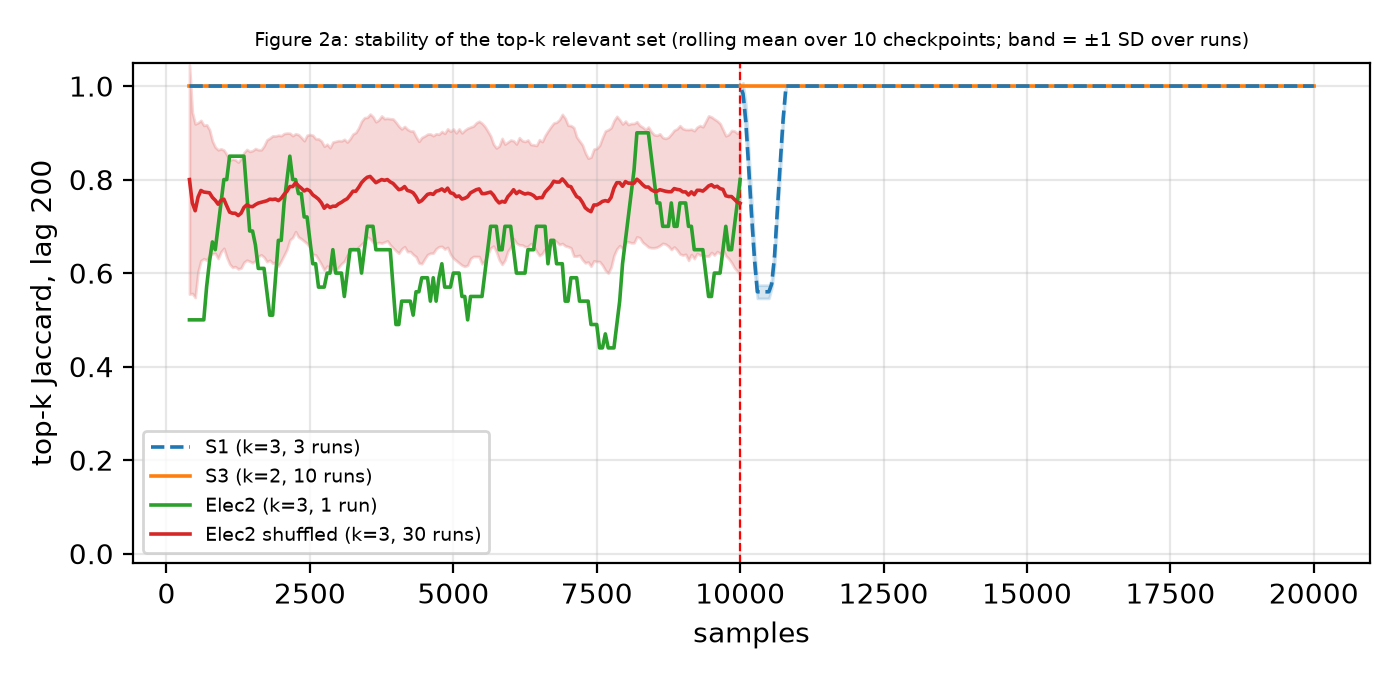

fig2a_jaccard_lag200_nodate.png


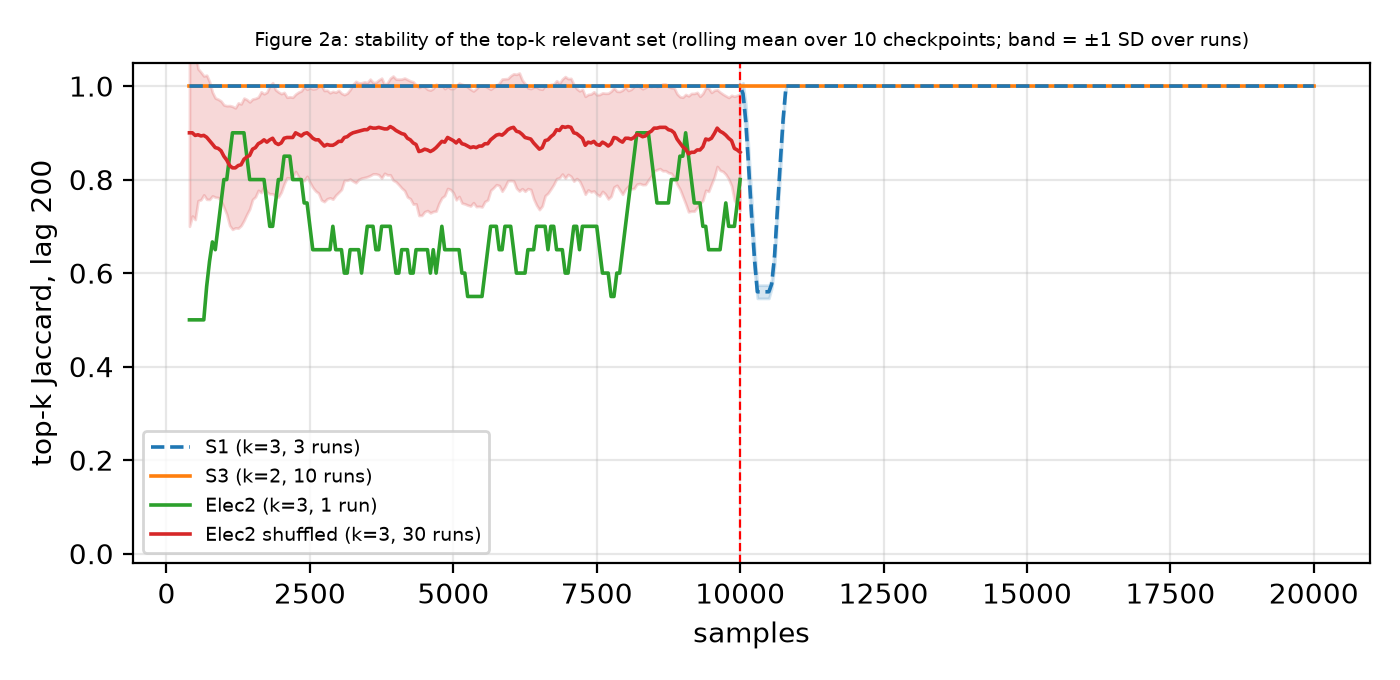

In [5]:
for name in ["fig2a_jaccard_lag200.png", "fig2a_jaccard_lag200_nodate.png"]:
    p = SQ1 / name
    if p.exists():
        print(name)
        display(Image(filename=str(p)))

> **Conclusion (section 6, Figure 2a).** Without `date`, Elec2 sits below the shuffled ±1 SD band for most of the stream (roughly samples 2500 to 7800, mostly 0.55 to 0.70 against about 0.88) and reaches the shuffled level only twice, near sample 1200 and near samples 8300 to 8500. With `date` the gap is smaller and Elec2 stays inside the band for part of the time. The same two excursions appear in both variants, so they are properties of the stream and not of one feature set; this notebook does not explain them. The S1 line shows the drift at 10,000 (Jaccard falls to about 0.55 and is back at 1.0 by about 10,800); that segment is excluded from the SQ1 statistics and belongs to the drift questions. Elec2 is one run, so the figure shows direction, not a distribution.

### Does the gap depend on the lag?

Mean Jaccard by lag. Lags 50, 100 and 150 overlap the 200-sample window and are inflated by shared data.

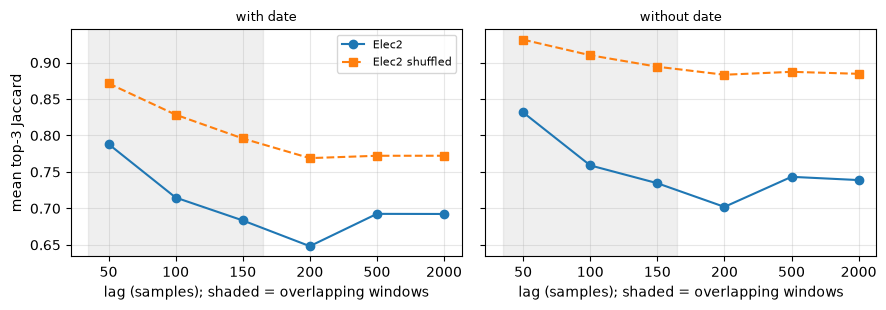

In [6]:
LAGS = [50, 100, 150, 200, 500, 2000]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, (label, sfx) in zip(axes, [("with date", ""), ("without date", "_nodate")]):
    try:
        rows = read_runs(sfx)
    except FileNotFoundError:
        ax.set_title(f"{label}: no data"); continue
    for cond, style in [("Elec2", "o-"), ("Elec2 shuffled", "s--")]:
        ax.plot(range(len(LAGS)), [values(rows, cond, f"jaccard@{l}").mean() for l in LAGS], style, label=cond)
    ax.axvspan(-0.3, 2.3, color="grey", alpha=0.12)
    ax.set_xticks(range(len(LAGS))); ax.set_xticklabels(LAGS)
    ax.set_title(label, fontsize=9); ax.set_xlabel("lag (samples); shaded = overlapping windows"); ax.grid(alpha=0.3)
axes[0].set_ylabel("mean top-3 Jaccard"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

> **Conclusion (lag profile).** Both curves fall from lag 50 to lag 200, which is the window overlap disappearing, and are flat from lag 200 to lag 2000. The gap between Elec2 and its shuffles is present at every lag (about 0.08 to 0.12 with `date`, 0.10 to 0.18 without) and does not shrink or grow with lag beyond 200. If relevance drifted slowly, the real curve should keep falling as the lag grows; it does not, which fits fast fluctuation in the ranking better than slow drift. The small rise of the real curve between lag 200 and lag 500 comes from a single run and should not be interpreted.

## 7. Reading the results

**What the data support.** On Elec2 the top-3 of G is less stable than in a shuffled copy of the same stream, with and without `date`, for every metric and every lag:

| Elec2 vs 30 shuffles (G, lag 200, k=3) | With `date` | Without `date` |
|---|---|---|
| Jaccard, real | 0.648 | 0.702 |
| Jaccard, shuffled | 0.769 ± 0.026 | 0.883 ± 0.024 |
| τ-b, real vs shuffled | 0.839 vs 0.897 | 0.874 vs 0.961 |
| Top-k switches per 1000 | 8.2 vs 5.1 | 6.7 vs 2.7 |
| Mean SD of weights | 0.043 vs 0.013 | 0.044 vs 0.013 |
| Exact one-sided p | 0.032 | 0.032 |

- Dropping `date` did **not** remove the effect; it made the gap larger, because in shuffled order `date` had been adding noise to G.
- The gap is about the same at lag 200 and lag 2000, so the instability looks like fast fluctuation of G, not slow drift accumulating. This is a hypothesis, not a result.
- Shuffling still gives about 3–5 top-k switches per 1000 samples: a 200-sample window is noisy even without any change. That is the noise floor.

**What the data do not support**

- **p = 0.032 is the minimum possible with 30 shuffles**, and Elec2 is a single stream tested against shuffles of itself. It says nothing about electricity data in general.
- **G does not depend on the rules.** It is computed from the labelled buffer, so SQ1 measures the stability of the relevance estimator on this stream, not of the learned rule base. The rule-level vector A is constant in most runs here and was therefore not used.
- **Class-mix confound (not yet tested).** Elec2 labels are autocorrelated, so a real 200-sample window can be class-imbalanced while a shuffled one is not. The between/within variance ratio gets noisier when the class mix shifts, so part of the gap may come from that, not from relevance changing. A check: log the class proportion per window and see whether it explains the Jaccard drops.
- **S1 and S3 are at 1.000 at every lag.** They pass the sanity check but cannot discriminate between conditions.
- **The model is at or near the majority rate** (Elec2 0.59 vs majority 0.567), so "stable relevance" here does not mean "useful relevance".

> **Conclusion (section 7).** The supported claim is narrow: on Elec2, the top-3 of G changes more between snapshots 200 samples apart than it does in shuffled copies of the same stream, with and without `date`, on every metric and at every lag. As an illustration, if disagreements are one-feature swaps (Jaccard 0.5), a mean of 0.70 means about 6 in 10 snapshot pairs disagree on one of the three features, against about 2 in 10 for the shuffles (0.88); treat this as an order-of-magnitude reading, not a measured count. The claim stops at the stream and at the estimator: one stream, a p-value at its floor, a G that does not depend on the rules, and an untested class-mix explanation. "Stable relevance" also does not mean "useful relevance", since the model is near the majority rate.

## 8. Reproduce

From the repo root, with the venv active:

```powershell
python run_relevance.py --config wf1_stability/configs/s3.json
python run_relevance.py --config wf1_stability/configs/elec2.json
python run_relevance.py --config wf1_stability/configs/elec2_shuffled.json
python run_relevance.py --config wf1_stability/configs/elec2_nodate.json
python run_relevance.py --config wf1_stability/configs/elec2_shuffled_nodate.json
python wf1_stability/analyze_sq1.py
python wf1_stability/analyze_sq1.py --suffix _nodate
python tests/test_stability.py
```

S1 comes from [configs/mve.json](../configs/mve.json) (`python run_relevance.py --config configs/mve.json`).

> **Conclusion (section 8).** The whole analysis can be rebuilt from five configs and two analysis commands (about 10 minutes, mostly the 60 shuffled runs), and the tests cover the metric functions, so every number in this notebook can be regenerated.

## 9. Text for the report

**SQ1 row of Table 1.** *SQ1, stability of G.* Primary: top-k Jaccard at lag 200 (k=3). Elec2 0.70 [0.66, 0.74] vs 0.88 ± 0.02 for 30 shuffled copies (exact one-sided p = 0.032, the minimum possible with 30 shuffles); with `date` included, 0.65 vs 0.77 ± 0.03. The weights fluctuate about 3.4× more on the real stream (mean SD 0.044 vs 0.013). The S3 sanity check gives 1.00. Elec2 is one stream, so the result is not a general claim about electricity data.

> **Conclusion (section 9).** The Table 1 row carries the headline numbers with their limits attached. In one sentence: **the top-3 relevant features of G on Elec2 are measurably less stable over time than a shuffled copy of the same data would give (Jaccard@200 0.70 vs 0.88; 0.65 vs 0.77 with `date`; exact p = 0.032 in both), while on stationary synthetic streams they are perfectly stable (1.00).**

## 10. Still open

- Class-mix control (section 7).
- Reformulate H3 as G versus A lag, and add a shuffled-weights control to SQ4 (the `NO_W` ablation is confounded with weight scale).
- A stream where the model clearly beats the majority rate.

> **Conclusion (section 10).** The class-mix control is the one open item that can change the SQ1 reading, so it comes first: if window class imbalance explains the Jaccard drops, the gap is not about relevance. The other two items concern H3, SQ4 and the choice of stream, not SQ1.

## 11. Minês Talk

### Workflow 1 (SQ1): what was done and what we found

 My part of the project is to measure whether the feature-relevance weights of UnimNeuron stay stable over time. Everything is implemented as an observer next to the professor's baseline on branch `mines`. `ENF_UnimNeuron_Safe.py`, `exp_sota_comparison.py` and `exp_ablation.py` are untouched.

#### 1. Reading the baseline

Reading the code before measuring anything gave findings the group should know about:

- **Two kinds of weights.** G (`current_feature_weights`) is recomputed every 50 samples from the last 200 samples, using a between/within-class variance ratio scaled to [0.2, 1.0]. Each rule keeps its own weight vector, a frozen copy of G at the moment the rule was created. The rule-level vector A is the support-weighted mean of those.
- **The model is deterministic**, so one run per stream is enough.
- **With `max_rules=5` and `min_rules_for_merge=5`, merging never fires.** Pruning is the only way a rule disappears.
- **Three hyperparameters have no effect:** `safe_threshold`, `min_firing_for_update` and `drift_sensitivity` are ignored.
- **The baseline's `min_max_scale` uses the whole stream**, so it leaks future information.
- **The baseline's `ConceptDrift_Agrawal` has no real drift,** because both halves use classification function 0.
- **The model sits at or near the majority rate on every stream** (Elec2 0.591 against a majority of 0.567), so "stable relevance" cannot be read as "useful relevance".
- **`enfs_uni0_evolving.py` is missing from the repo,** although `exp_sota_comparison.py` imports it unconditionally.
- **The `NO_W` ablation is confounded with weight scale.** It needs a shuffled-weights control.

#### 2. Tooling

- **Non-intrusive logging** (`relevance/`, `run_relevance.py`). Tests show it changes no prediction, rule count, weight or rule state, that no label leaks into earlier predictions, and that our loop reproduces the baseline's predictions and rule counts exactly.
- **Ground truth for drift.** I re-implemented the Agrawal generator and checked all 10 classification functions against river. This gives a stream whose true relevant features change at a known point.
- **Stability metrics and statistics** (`relevance/stability.py`, `relevance/stats.py`):
  - metrics: top-k Jaccard, τ-b, weighted τ, Spearman, top-k switches per 1000, per-feature SD;
  - statistics: bootstrap and block-bootstrap CIs, Wilcoxon with rank-biserial, Holm correction, and an exact shuffle p-value;
  - tests, including one where the top-k is stable but the other features are shuffled. There Jaccard is 1.0 and τ-b about 0.37, which shows why both are needed.

#### 3. Design decisions

- **Primary metric:** top-k Jaccard of G at lag 200 (k=2 on synthetic, k=3 on Elec2). Lag 200 is the first lag where two snapshots share no samples. Lags below 200 are reported with their overlap (lag 50 = 75%).
- **Stationary segments only,** with the 200-sample buffer flushed after any drift.
- **Elec2 preprocessing:** fixed domain scaling (`day` → (day−1)/6, other features as they are). Accuracy is 0.5915 against the baseline's 0.591, so it does not distort the model. Expanding min-max would have collapsed the monotone `date` feature in the original order but not when shuffled.
- **Inference:** Elec2 is one stream, so I compare it with 30 shuffled copies of itself using an exact one-sided p-value, (1 + hits) / (N + 1). With 10 shuffles the smallest p would be 0.091. With 30 it is 0.032. I also repeated everything without `date`.

#### 4. Results

| G, lag 200, k=3 | With `date` | Without `date` |
|---|---|---|
| Jaccard, Elec2 | 0.648 [0.601, 0.693] | 0.702 [0.663, 0.744] |
| Jaccard, 30 shuffles | 0.769 ± 0.026 | 0.883 ± 0.024 |
| τ-b, Elec2 vs shuffles | 0.839 vs 0.897 | 0.874 vs 0.961 |
| Top-k switches per 1000 | 8.2 vs 5.1 | 6.7 vs 2.7 |
| Mean SD of weights | 0.043 vs 0.013 | 0.044 vs 0.013 |
| Exact one-sided p | 0.032 | 0.032 |

- **On stationary synthetic streams (S1, S3) the top-k is perfectly stable** (Jaccard 1.000 at every lag). The low τ-b there (0.356 on S3) comes from the ordering of the irrelevant features, not from instability.
- **On Elec2 the top-3 of G is less stable than in a shuffled copy,** on every metric and every lag. None of the 30 shuffles reaches the real value. Without `date` the gap is larger (z = −7.5 against −4.7 with it), so `date` does not explain the result.
- **The gap is about the same at lag 200 and lag 2000.** That fits fast fluctuation of the ranking better than slow drift, but it is a hypothesis.
- **Shuffling still produces 3 to 5 top-k switches per 1000.** That is the noise floor of a 200-sample window.
- **Figure 2a:** without `date`, Elec2 sits below the shuffled band for most of the stream (roughly samples 2500 to 7800) and reaches it only twice, near 1200 and near 8300 to 8500. With `date` the gap is smaller. The figure shows direction; Elec2 is a single run.

#### 5. Limits

- **One stream, and p = 0.032 is the floor** for 30 shuffles. The result is not a claim about electricity data in general.
- **G is computed from the labelled buffer and does not depend on the rules,** so SQ1 measures the stability of the relevance estimator on this stream, not of the learned rule base. On Elec2 the rule base does evolve (62 rules created, 57 removed) and A carries learned weights, which matters for H3.
- **Class-mix confound, not yet tested.** Elec2 labels are autocorrelated, so a real 200-sample window can be class-imbalanced while a shuffled one is not. That alone could make G noisier on the real stream.
- **The synthetic streams cannot discriminate between conditions,** because they sit at the ceiling.

#### 6. Open items

- A class-mix control, which could change the SQ1 reading.
- Reformulate H3 as G against A lag, and add a shuffled-weights control to SQ4.
- A stream where the model clearly beats the majority rate.

All code, configs, tables, Figure 2a and the notebook `notebooks/sq1_stability.ipynb` are on branch `mines`.